<a href="https://colab.research.google.com/github/Aaarkun/rfm-transaction-analytics/blob/main/%D0%9B%D0%A03_%D0%97%D0%B0%D1%85%D0%B0%D1%80%D0%B5%D0%B2%D0%B8%D1%87_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import kagglehub

## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [45]:
# Ваш код:
# Завантажте файл і збережіть дані у DataFrame `df`.
drive_id = "1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd"
drive_url = f"https://drive.google.com/uc?export=download&id={drive_id}"

df = pd.read_csv(drive_url)
df.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.5996,0,5,262382.8523
1,4272,3,3,2016,4.7530,1,6,985260.8545
2,3592,1,2,2016,3.6348,0,9,777977.3901
3,966,1,2,1977,2.7307,1,8,229698.9187
4,4926,2,1,1993,4.6991,0,8,1041740.8589


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [44]:
# Ваш код:
# Завантажте файл і збережіть дані у DataFrame
path = kagglehub.dataset_download("prokshitha/home-value-insights")
csv_file = next(f for f in os.listdir(path) if f.endswith(".csv"))
df= pd.read_csv(os.path.join(path, csv_file))
df.head()

Using Colab cache for faster access to the 'home-value-insights' dataset.


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.5996,0,5,262382.8523
1,4272,3,3,2016,4.7530,1,6,985260.8545
2,3592,1,2,2016,3.6348,0,9,777977.3901
3,966,1,2,1977,2.7307,1,8,229698.9187
4,4926,2,1,1993,4.6991,0,8,1041740.8589


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [37]:
# Ваш код:
# Виведіть кілька перших рядків та загальну інформацію про DataFrame.display(df.head())
print()
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [36]:
# Ваш код:
# Порахуйте кількість дублікатів.
n_dup = df.duplicated().sum()
print(f"Кількість дубльованих рядків: {n_dup}")

Кількість дубльованих рядків: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [42]:
# Ваш код:
# Виведіть кількість пропусків для кожної ознаки.
missing = df.isna().sum()
print("Пропущені значення по стовпцях:")
print(missing)
print(f"\nУсього пропусків: {missing.sum()}")

Пропущені значення по стовпцях:
Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64

Усього пропусків: 0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [18]:
# Ваш код:
# Отримайте описову статистику датасету.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Square_Footage,1000.0000,2815.4220,1255.5149,503.0000,1749.5000,2862.5000,3849.5000,4999.0000
Num_Bedrooms,1000.0000,2.9900,1.4276,1.0000,2.0000,3.0000,4.0000,5.0000
Num_Bathrooms,1000.0000,1.9730,0.8203,1.0000,1.0000,2.0000,3.0000,3.0000
Year_Built,1000.0000,1986.5500,20.6329,1950.0000,1969.0000,1986.0000,2004.2500,2022.0000
Lot_Size,1000.0000,2.7781,1.2979,0.5061,1.6659,2.8097,3.9233,4.9893
Garage_Size,1000.0000,1.0220,0.8150,0.0000,0.0000,1.0000,2.0000,2.0000
Neighborhood_Quality,1000.0000,5.6150,2.8871,1.0000,3.0000,6.0000,8.0000,10.0000
House_Price,1000.0000,618861.0186,253568.0584,111626.8534,401648.2289,628267.2911,827141.2776,1108236.8363


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [17]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Neighborhood_Quality`.
df["Neighborhood_Quality"].value_counts().sort_index()

,count
Neighborhood_Quality,
1,91
2,105
3,85
4,99
5,109
6,101
7,102
8,97
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

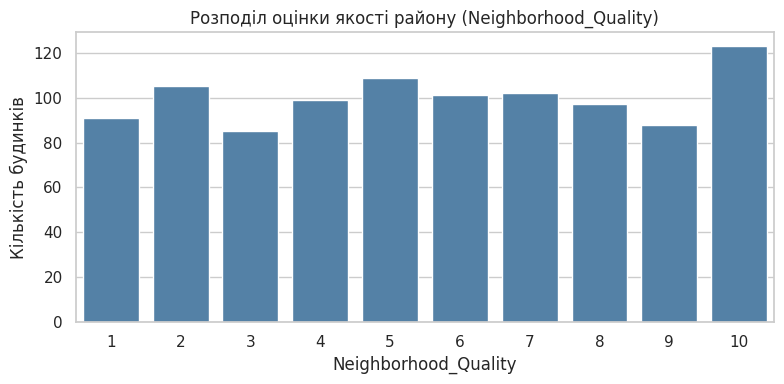

In [16]:
# Ваш код:
# Побудуйте countplot або іншу відповідну діаграму.
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Neighborhood_Quality", color="steelblue")
plt.title("Розподіл оцінки якості району (Neighborhood_Quality)")
plt.xlabel("Neighborhood_Quality")
plt.ylabel("Кількість будинків")
plt.tight_layout()
plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [40]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Num_Bathrooms`.
df["Num_Bathrooms"].value_counts().sort_index()

,count
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

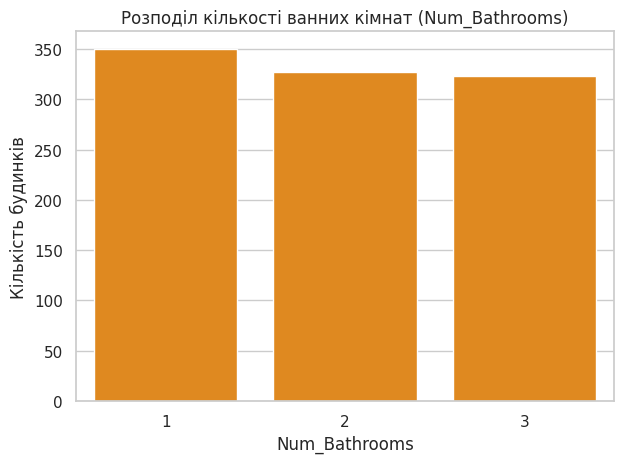

In [41]:
# Ваш код:
# Побудуйте відповідну діаграму.plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Num_Bathrooms", color="darkorange")
plt.title("Розподіл кількості ванних кімнат (Num_Bathrooms)")
plt.xlabel("Num_Bathrooms")
plt.ylabel("Кількість будинків")
plt.tight_layout()
plt.show()

### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

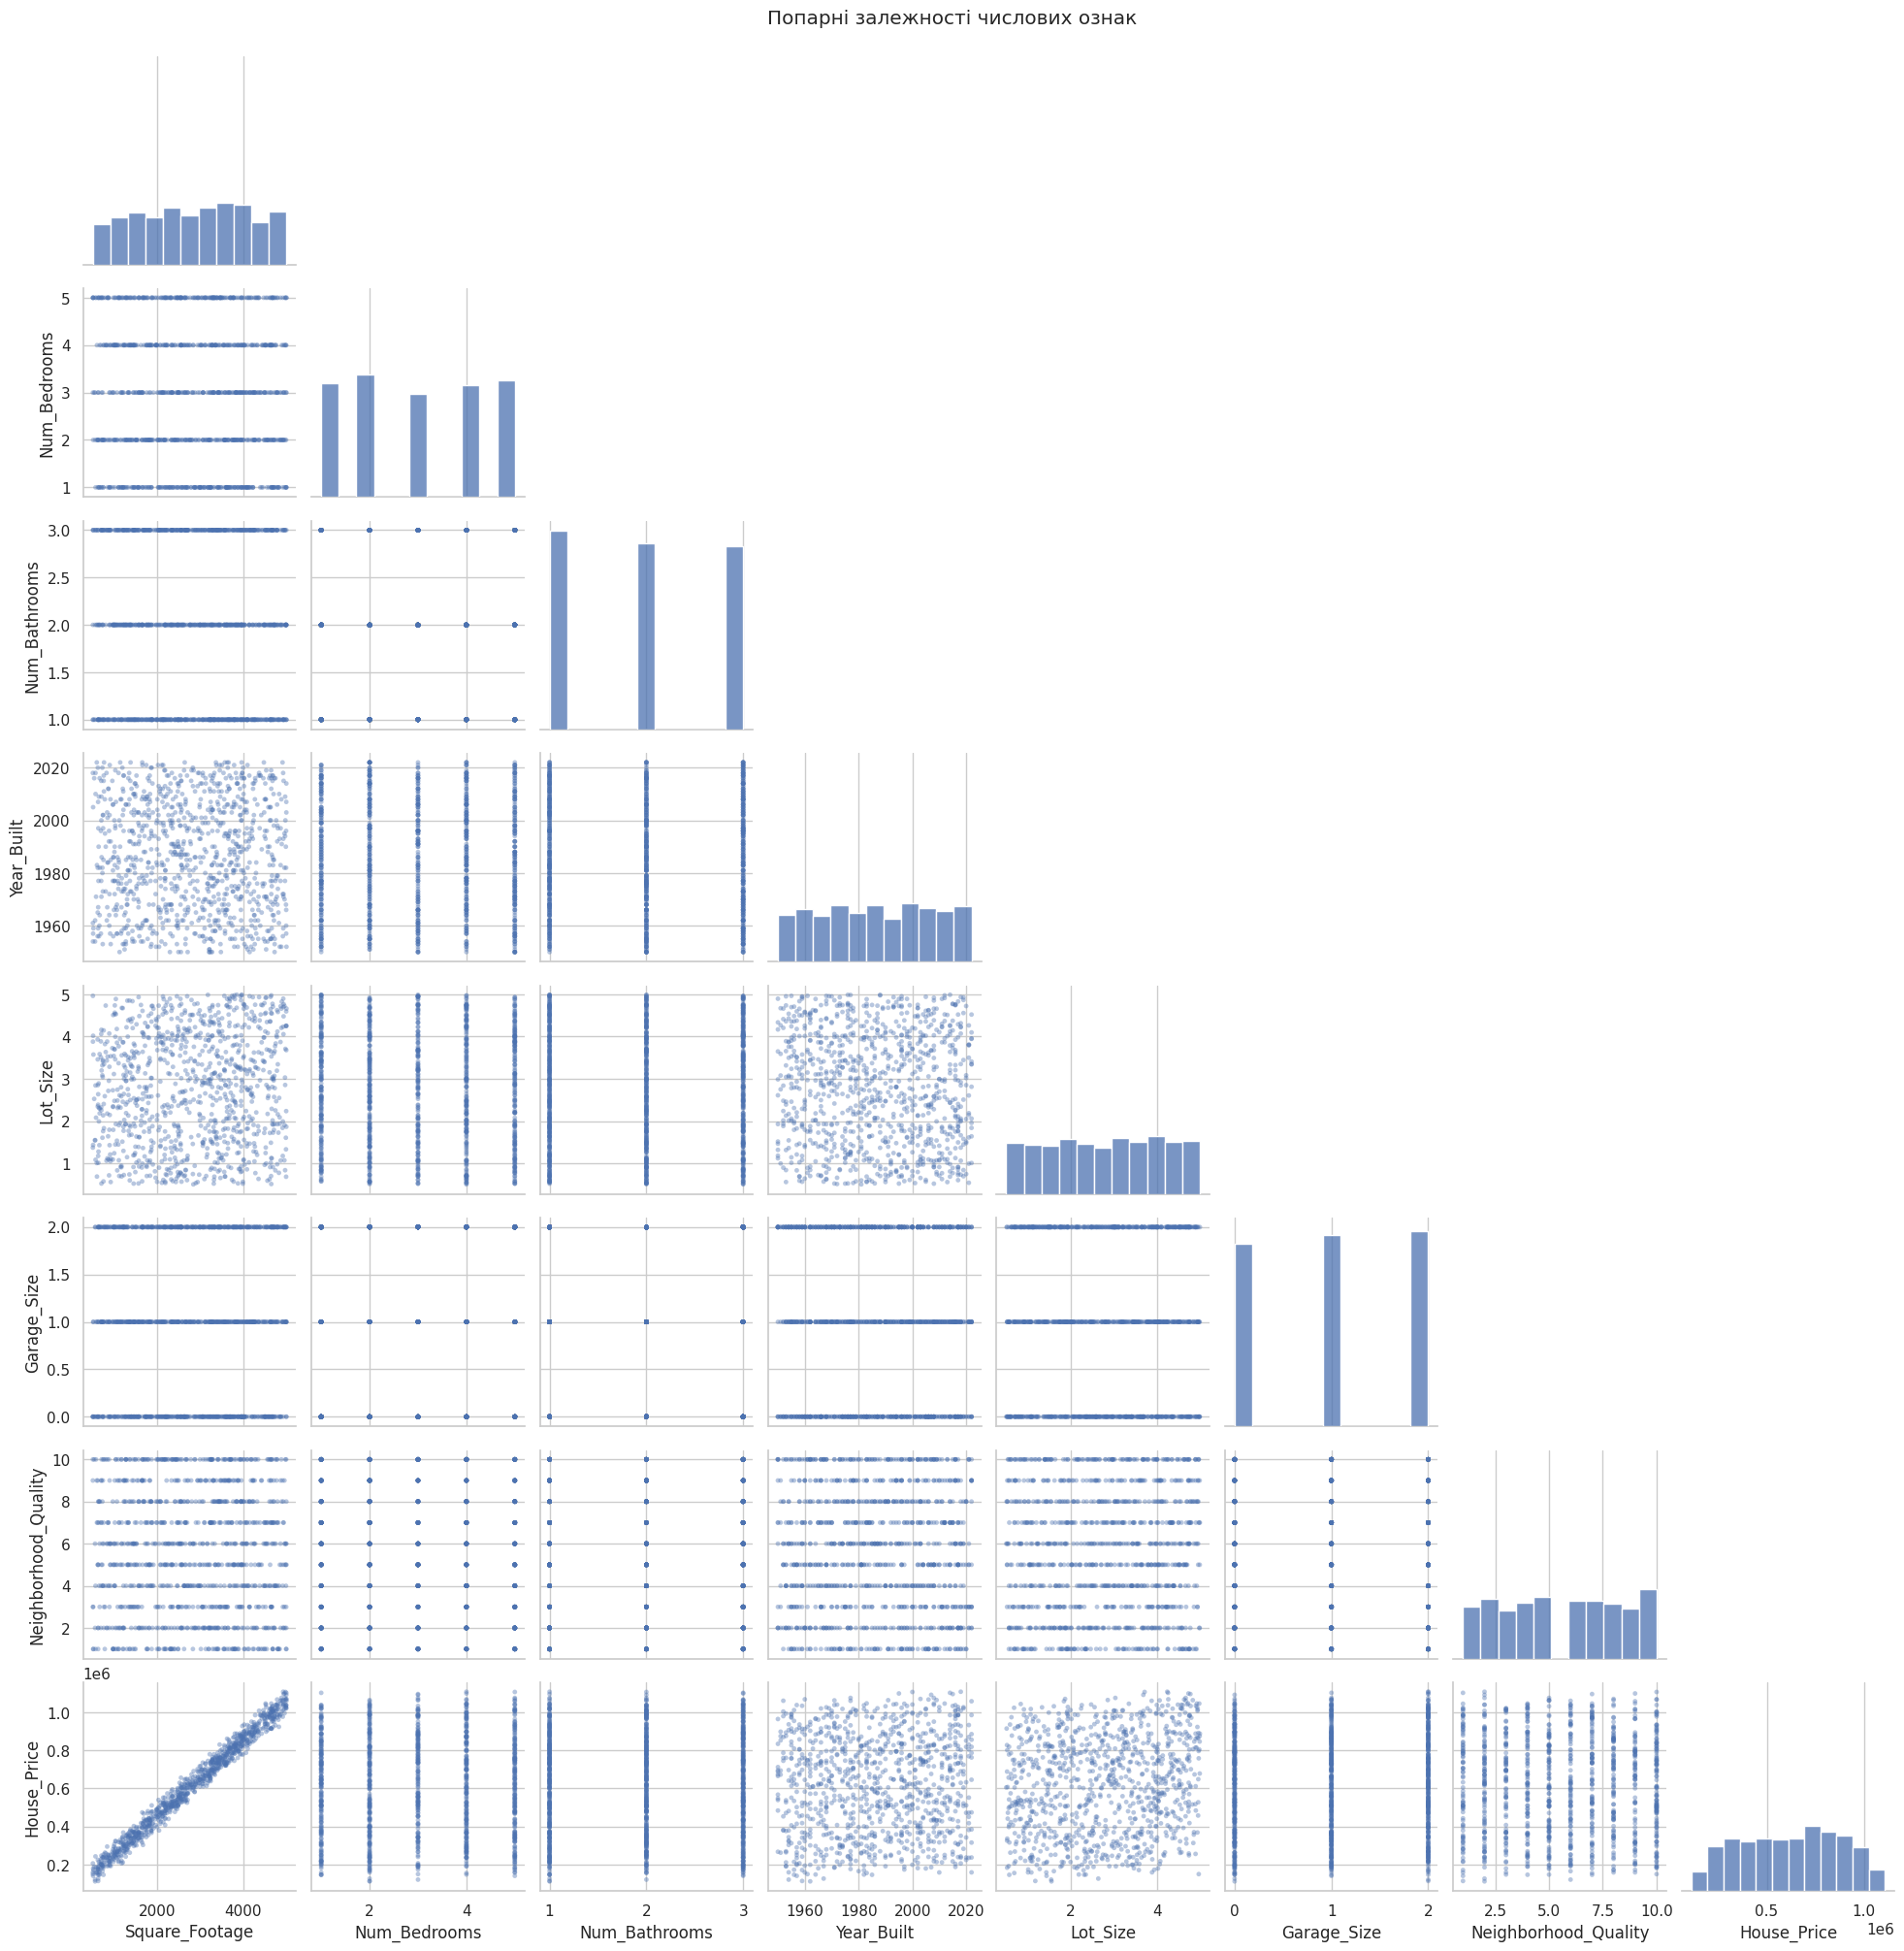

In [22]:
# Ваш код:
# Побудуйте pairplot або іншу попарну візуалізацію.
g = sns.pairplot(df, corner=True, diag_kind="hist",
                 plot_kws={"alpha": 0.4, "s": 12, "edgecolor": "none"})
g.figure.suptitle("Попарні залежності числових ознак", y=1.01)
plt.show()

**Аналіз попарних графіків.**
- Єдина виразна залежність - майже ідеальна лінійна між `Square_Footage` і `House_Price` (кореляція ≈ 0.99).
- `Lot_Size` має слабкий додатний зв'язок із ціною (≈ 0.16); `Garage_Size` і `Year_Built` - дуже слабкий (≈ 0.05).
- `Num_Bedrooms`, `Num_Bathrooms` і `Neighborhood_Quality` майже не пов'язані з ціною (|r| < 0.02).
- Ознаки між собою практично не корелюють (|r| ≤ 0.11), тож мультиколінеарності немає. Дискретні ознаки розподілені майже рівномірно.

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

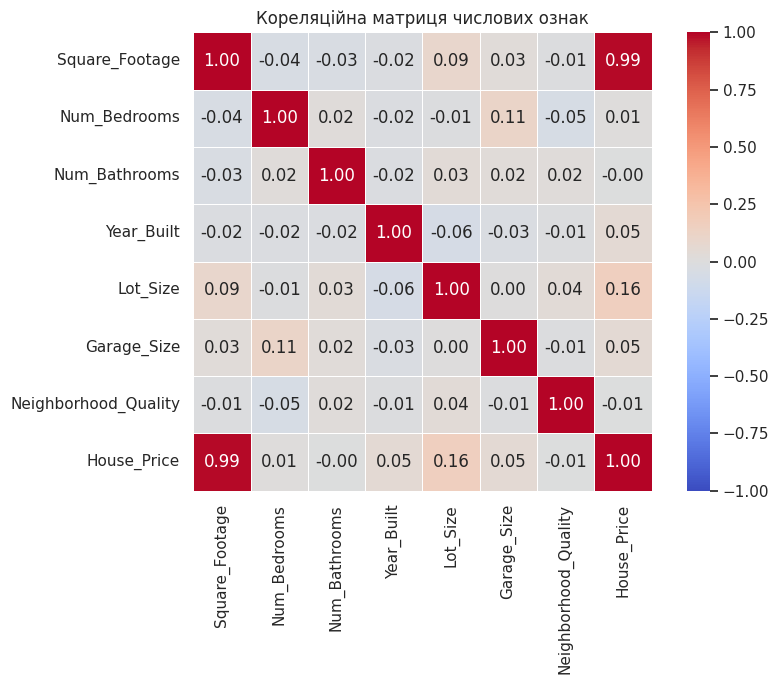

In [24]:
# Ваш код:
# Обчисліть кореляційну матрицю та побудуйте heatmap.
corr = df.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5)
plt.title("Кореляційна матриця числових ознак")
plt.tight_layout()
plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [25]:
# Ваш код:
# Виведіть кореляції ознак із `House_Price`.
corr_target = (df.corr(numeric_only=True)["House_Price"]
                 .drop("House_Price")
                 .sort_values(ascending=False))
corr_target

,House_Price
Square_Footage,0.9913
Lot_Size,0.1604
Garage_Size,0.0521
Year_Built,0.0520
Num_Bedrooms,0.0146
Num_Bathrooms,-0.0019
Neighborhood_Quality,-0.0078


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [26]:
# Ваш код:
# Імпортуйте необхідні класи та функції зі scikit-learn.
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [27]:
# Ваш код:
# Створіть `X` та `y`.
X = df.drop(columns="House_Price")
y = df["House_Price"]
print("X:", X.shape, "| y:", y.shape)
print("Ознаки:", list(X.columns))

X: (1000, 7) | y: (1000,)
Ознаки: ['Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built', 'Lot_Size', 'Garage_Size', 'Neighborhood_Quality']


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [28]:
# Ваш код:
# Створіть `X_train`, `X_test`, `y_train`, `y_test`.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Навчальна вибірка: {X_train.shape[0]} рядків")
print(f"Тестова вибірка:   {X_test.shape[0]} рядків")

Навчальна вибірка: 800 рядків
Тестова вибірка:   200 рядків


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [29]:
# Ваш код:
# Створіть словник або іншу структуру з п’ятьма моделями.
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(random_state=42)),
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(random_state=42)),
    ]),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
list(models)

['Linear Regression', 'Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting']

### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [30]:
# Ваш код:
# Навчіть усі моделі, отримайте прогнози та метрики на тестовій вибірці.
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results.append({
        "Модель": name,
        "R2": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
    })

results_df = pd.DataFrame(results).set_index("Модель")
results_df.sort_values("R2", ascending=False)

,R2,MAE,MSE
Модель,,,
Linear Regression,0.9984,8174.5836,101434798.5056
Lasso,0.9984,8174.7484,101436558.1801
Ridge,0.9984,8241.5869,102480990.0087
Gradient Boosting,0.9965,12305.2176,224965597.8451
Random Forest,0.9939,16114.2896,394131747.4460


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

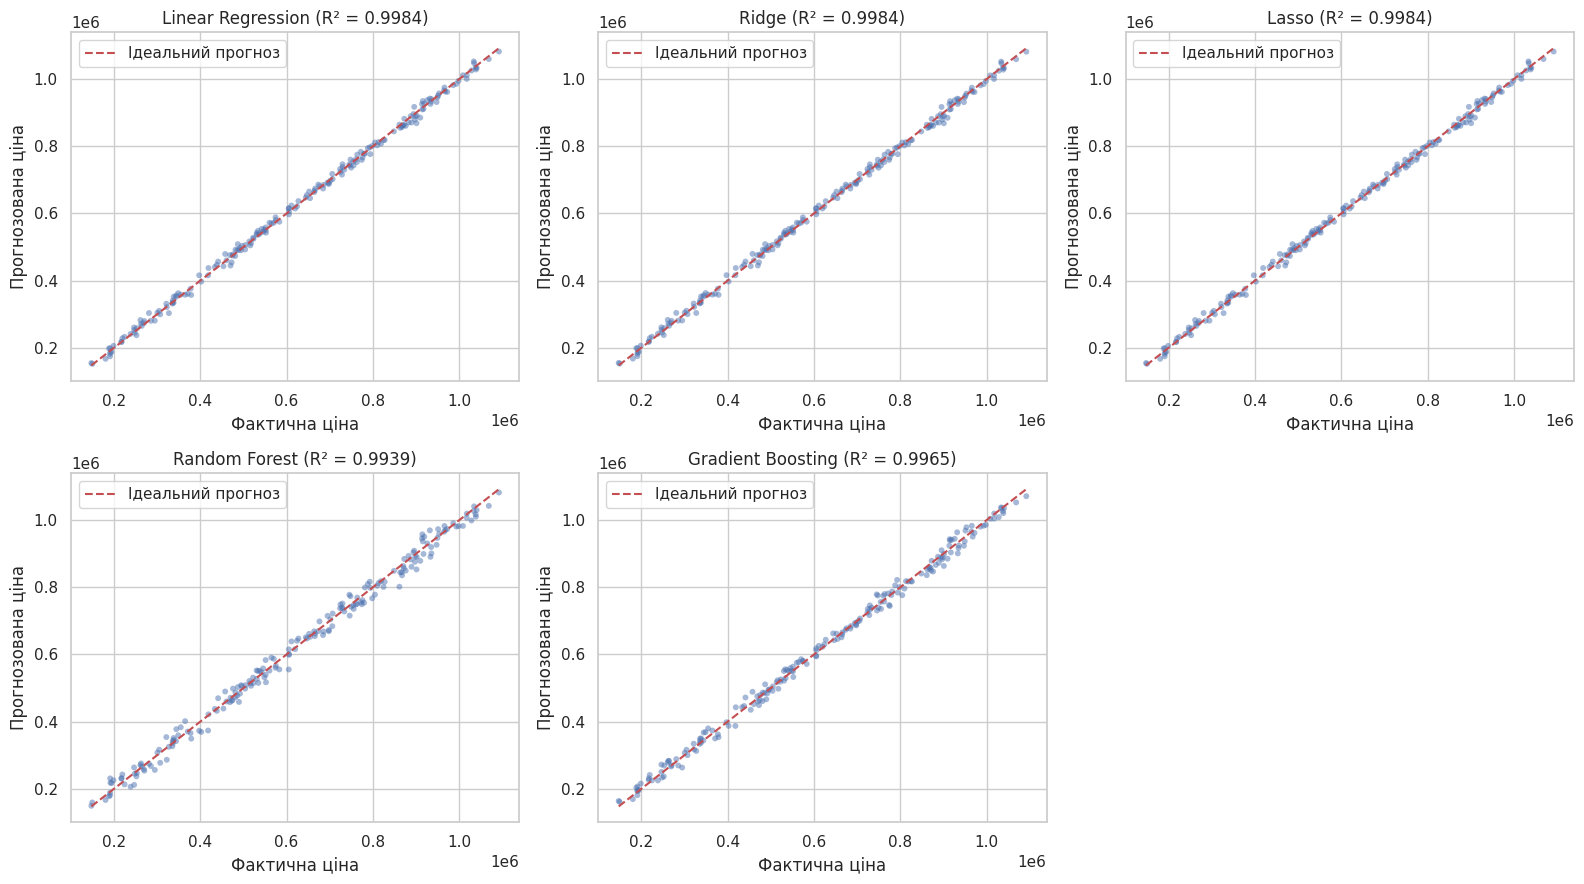

In [31]:
# Ваш код:
# Побудуйте окремий графік для кожної моделі.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()
lims = [y_test.min(), y_test.max()]

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.5, s=18, edgecolor="none")
    ax.plot(lims, lims, "r--", label="Ідеальний прогноз")
    r2 = results_df.loc[name, "R2"]
    ax.set_title(f"{name} (R² = {r2:.4f})")
    ax.set_xlabel("Фактична ціна")
    ax.set_ylabel("Прогнозована ціна")
    ax.legend(loc="upper left")

for ax in axes[len(predictions):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [32]:
# Ваш код:
# Створіть сітку параметрів, GridSearchCV і знайдіть найкращі параметри.
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_features": ["sqrt", "log2", 1.0],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
}

grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Найкращі параметри:", grid.best_params_)
print(f"Найкращий середній R² на крос-валідації: {grid.best_score_:.4f}")

Найкращі параметри: {'max_depth': None, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 300}
Найкращий середній R² на крос-валідації: 0.9920


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [33]:
# Ваш код:
# Навчіть оптимізований Random Forest та обчисліть метрики.
best_rf = RandomForestRegressor(**grid.best_params_, random_state=42)
best_rf.fit(X_train, y_train)
y_pred_best = best_rf.predict(X_test)

best_metrics = {
    "R2": r2_score(y_test, y_pred_best),
    "MAE": mean_absolute_error(y_test, y_pred_best),
    "MSE": mean_squared_error(y_test, y_pred_best),
}
for k, v in best_metrics.items():
    print(f"{k}: {v:,.4f}")

R2: 0.9940
MAE: 15,930.6379
MSE: 384,826,810.1531


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [34]:
# Ваш код:
# Виведіть результати двох моделей у зручному для порівняння вигляді.
comparison = pd.DataFrame({
    "Random Forest (базовий)": results_df.loc["Random Forest"],
    "Random Forest (оптимізований)": pd.Series(best_metrics),
})
comparison["Зміна"] = comparison["Random Forest (оптимізований)"] - comparison["Random Forest (базовий)"]
comparison

,Random Forest (базовий),Random Forest (оптимізований),Зміна
R2,0.9939,0.9940,0.0001
MAE,16114.2896,15930.6379,-183.6518
MSE,394131747.4460,384826810.1531,-9304937.2929


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

Так, якість трохи покращилась, але зміни дуже малі. Підбір дав `n_estimators=300`, `max_features=1.0`, `max_depth=None`, `min_samples_split=2` (середній R² на крос-валідації 0.9920).

| Метрика | Базова модель | Оптимізована | Зміна |
|---|---|---|---|
| R² | 0.99388 | 0.99402 | +0.00014 |
| MAE | 16 129.96 | 15 946.14 | -183.82 (≈ -1.1%) |
| MSE | 394 541 219 | 385 452 142 | -9 089 078 (≈ -2.3%) |

Змінились усі три метрики, і всі в кращий бік: R² зріс, MAE та MSE зменшились. Базова модель і так була дуже точною, тому виграш майже непомітний. Оптимізовану модель використовувати доцільно, бо вона не гірша і трохи точніша, але вона дорожча в навчанні (300 дерев). Зауваження: найкращі значення лежать на межі сітки (`n_estimators=300`, `max_features=1.0`, `min_samples_split=2`), тож розширення сітки могло б дати ще невеликий приріст. При цьому навіть оптимізований Random Forest поступається лінійним моделям.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [35]:
# Ваш код:
# Сформуйте DataFrame з фактичними та прогнозованими значеннями і розрахуйте похибку у %.
lr_pred = predictions["Linear Regression"]

pred_table = pd.DataFrame({
    "Фактична ціна": y_test.values,
    "Прогнозована ціна": lr_pred,
})
pred_table["Похибка, %"] = (
    (pred_table["Прогнозована ціна"] - pred_table["Фактична ціна"]).abs()
    / pred_table["Фактична ціна"] * 100
)

display(pred_table.sample(10, random_state=42).round(2))
print(f"\nСередня абсолютна похибка у відсотках (MAPE) на тестовій вибірці: {pred_table['Похибка, %'].mean():.2f}%")

,Фактична ціна,Прогнозована ціна,"Похибка, %"
95,1068538.1100,1059729.0200,0.8200
15,194353.7400,187868.5500,3.3400
30,270230.6400,279715.8200,3.5100
158,986006.8600,981949.2700,0.4100
128,953339.7300,957382.9500,0.4200
115,914555.7500,909764.2700,0.5200
69,746167.7300,742469.1400,0.5000
170,646766.2900,654445.5500,1.1900
174,523323.0700,524605.4400,0.2500
45,1008539.1600,1011343.6400,0.2800



Середня абсолютна похибка у відсотках (MAPE) на тестовій вибірці: 1.66%


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

1. **Побудовані моделі.** П'ять моделей регресії: Linear Regression, Ridge, Lasso (з `StandardScaler` у `Pipeline`), Random Forest та Gradient Boosting; Random Forest додатково оптимізовано через `GridSearchCV`.
2. **Найкраща модель.** Linear Regression: R² = 0.9984, MAE ≈ 8 175, MSE ≈ 1.01·10⁸. Lasso показала практично те саме, Ridge трохи гірша (MAE ≈ 8 242). Gradient Boosting (R² = 0.9965, MAE ≈ 12 305) і Random Forest (R² = 0.9939, MAE ≈ 16 130) поступаються лінійним моделям. Причина в самих даних: ціна майже лінійно залежить від `Square_Footage` (кореляція 0.99), а лінійні моделі найкраще відтворюють таку залежність.
3. **Вплив підбору гіперпараметрів.** Оптимізований Random Forest покращив R² з 0.99388 до 0.99402, MAE зменшився на ≈ 1.1%, MSE на ≈ 2.3%. Покращення невелике і не змінює порядок моделей: лінійні моделі лишаються найкращими.
4. **Точність прогнозів.** На тестовій вибірці (200 будинків) Linear Regression дає середню абсолютну похибку ≈ 1.66% від ціни. Для вибірки з 10 випадкових рядків похибки лежать у межах від 0.25% до 3.5%; більші відсоткові похибки трапляються в дешевших будинках, бо абсолютна помилка ділиться на меншу ціну.
5. **Фактори, що впливають на якість прогнозування.** Визначальна ознака - площа будинку; `Lot_Size` дає слабкий внесок, решта ознак майже не пов'язана з ціною. Для реальної нерухомості на якість впливали б також розташування, стан і оздоблення, ринкова ситуація та час продажу, яких у датасеті немає. Дані тут, імовірно, синтетичні (рівномірні розподіли, відсутність пропусків і дублікатів), тому такий високий R² не варто переносити на реальні ринкові дані. Також варто пам'ятати про обмежений обсяг вибірки (1000 рядків) і одне випадкове розбиття train/test.